# 🛒 E-Commerce Sales Analytics — Superstore Dataset

**Goal:** analyze three years of transactional sales data from a US retail superstore to uncover
actionable insights on sales performance, profitability drivers, customer value, and regional trends —
and to forecast near-term sales.

**Business questions this analysis answers:**
1. How are sales and profit trending over time, and is the business seasonal?
2. Which product categories/sub-categories drive revenue — and which ones quietly destroy profit?
3. Does our discounting strategy help or hurt profitability?
4. Which customers are most valuable, and which are at risk of churning?
5. Which US states/regions are the strongest and weakest performers?
6. What should we expect for sales over the next few months?

> 📊 A companion **interactive Streamlit dashboard** (`dashboard/app.py`) lets you explore all of
> these questions live, with filters for date range, region, category and customer segment.
> This notebook focuses on the deep-dive analysis and written business insights.


## 1. Setup & Imports

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Make the `src` package (project root) importable from within notebooks/
sys.path.append(str(Path.cwd().parent))

from src.data_loader import load_clean_data
from src import sales_analysis as sa
from src import customer_segmentation as cs
from src import forecasting as fc
from src import geo_analysis as ga

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110


## 2. Data Loading & Overview

The dataset is a classic **"Sample Superstore"** retail dataset (US orders, 2014–2017),
commonly used for BI/analytics practice. All cleaning logic lives in `src/data_loader.py`
so the notebook, tests, and the Streamlit dashboard always use an identical, consistent dataset.

In [2]:
df = load_clean_data()
print(f"Rows: {len(df):,}  |  Columns: {df.shape[1]}  |  Date range: {df['Order Date'].min().date()} → {df['Order Date'].max().date()}")
df.head()

Rows: 9,994  |  Columns: 28  |  Date range: 2014-01-03 → 2017-12-30


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Quantity,Discount,Profit,Order Year,Order Month,Order Month Name,Order Quarter,Order Day of Week,Shipping Delay (Days),Profit Margin
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,2,0.00,41.9136,2016,11,Nov,4,1,3,0.1600
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,3,0.00,219.5820,2016,11,Nov,4,1,3,0.3000
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,2,0.00,6.8714,2016,6,Jun,2,6,4,0.4700
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,5,0.45,-383.0310,2015,10,Oct,4,6,7,-0.4000
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,2,0.20,2.5164,2015,10,Oct,4,6,7,0.1125


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Row ID                 9994 non-null   int64         
 1   Order ID               9994 non-null   str           
 2   Order Date             9994 non-null   datetime64[us]
 3   Ship Date              9994 non-null   datetime64[us]
 4   Ship Mode              9994 non-null   str           
 5   Customer ID            9994 non-null   str           
 6   Customer Name          9994 non-null   str           
 7   Segment                9994 non-null   str           
 8   Country                9994 non-null   str           
 9   City                   9994 non-null   str           
 10  State                  9994 non-null   str           
 11  Postal Code            9994 non-null   int64         
 12  Region                 9994 non-null   str           
 13  Product ID    

In [4]:
df.describe(include='number').T

,count,mean,std,min,25%,50%,75%,max
Row ID,9994.0,4997.500000,2885.163629,1.000,2499.25000,4997.5000,7495.7500,9994.000
Postal Code,9994.0,55190.379428,32063.693350,1040.000,23223.00000,56430.5000,90008.0000,99301.000
Sales,9994.0,229.858001,623.245101,0.444,17.28000,54.4900,209.9400,22638.480
Quantity,9994.0,3.789574,2.225110,1.000,2.00000,3.0000,5.0000,14.000
Discount,9994.0,0.156203,0.206452,0.000,0.00000,0.2000,0.2000,0.800
Profit,9994.0,28.656896,234.260108,-6599.978,1.72875,8.6665,29.3640,8399.976
Order Year,9994.0,2015.722233,1.123555,2014.000,2015.00000,2016.0000,2017.0000,2017.000
Order Month,9994.0,7.809686,3.284654,1.000,5.00000,9.0000,11.0000,12.000
Order Quarter,9994.0,2.882329,1.058086,1.000,2.00000,3.0000,4.0000,4.000
Order Day of Week,9994.0,3.206324,2.122925,0.000,1.00000,4.0000,5.0000,6.000


**Data quality note:** the dataset has **zero missing values** across all 21 original columns —
unusually clean for a real-world retail dataset, so no imputation was required. The main cleaning
work was type conversion (dates) and feature engineering (see `src/data_loader.py::clean_data`),
which adds: `Order Year/Month/Quarter`, `Shipping Delay (Days)`, and `Profit Margin`.

## 3. Key Performance Indicators (KPIs)

In [5]:
kpis = sa.kpi_summary(df)

print(f"💰 Total Sales:          ${kpis['total_sales']:,.0f}")
print(f"📈 Total Profit:         ${kpis['total_profit']:,.0f}")
print(f"📊 Overall Profit Margin:{kpis['overall_profit_margin']*100:6.1f}%")
print(f"🧾 Total Orders:         {kpis['total_orders']:,}")
print(f"👥 Total Customers:      {kpis['total_customers']:,}")
print(f"🛒 Avg Order Value:      ${kpis['avg_order_value']:,.2f}")

💰 Total Sales:          $2,297,201
📈 Total Profit:         $286,397
📊 Overall Profit Margin:  12.5%
🧾 Total Orders:         5,009
👥 Total Customers:      793
🛒 Avg Order Value:      $458.61


> **Insight:** the business is profitable overall (~12.5% margin), but as we'll see below,
> this headline number hides categories and states that are actually **losing money**.

## 4. Sales & Profit Trend Over Time

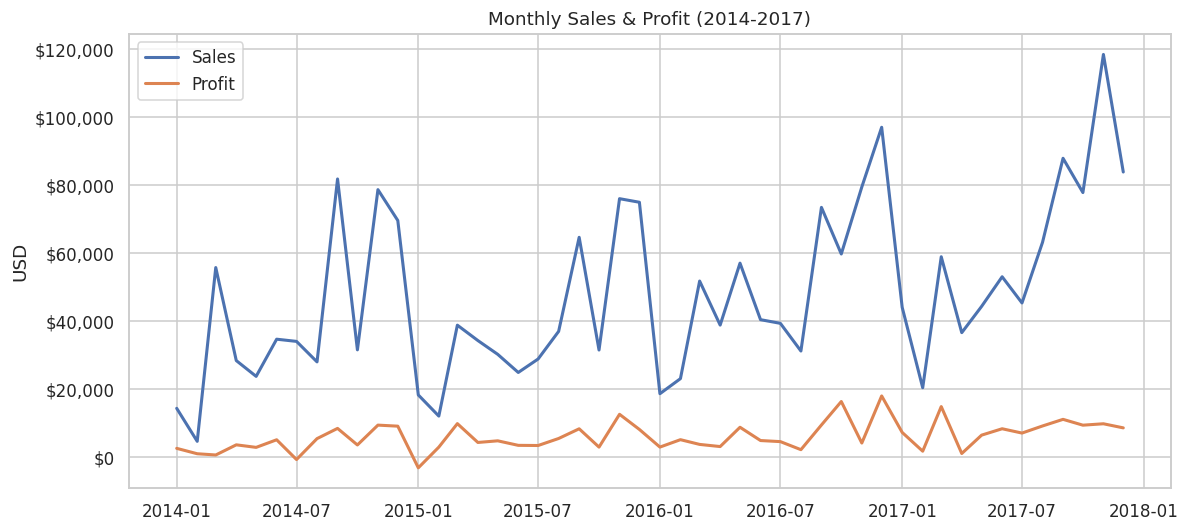

In [6]:
ts = sa.yearly_monthly_trend(df)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(ts["Year-Month"], ts["Sales"], label="Sales", linewidth=2)
ax.plot(ts["Year-Month"], ts["Profit"], label="Profit", linewidth=2)
ax.set_title("Monthly Sales & Profit (2014-2017)")
ax.set_ylabel("USD")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
ax.legend()
plt.tight_layout()
plt.show()

**Insight — strong, recurring seasonality:** sales consistently spike every **November–December**
(holiday shopping season) and dip in **January–February**. This pattern repeats every year, which is
exactly the signal the forecasting model in Section 9 uses. *Recommendation: align inventory
purchasing and marketing spend with this cycle instead of spreading budget evenly across the year.*

## 5. Category & Sub-Category Analysis

In [7]:
cat = sa.by_category(df)
cat["Profit Margin %"] = (cat["Profit"] / cat["Sales"] * 100).round(1)
cat.sort_values("Sales", ascending=False)

,Category,Sales,Profit,Orders,Profit Margin %
2,Technology,836154.0330,145454.9481,1544,17.4
0,Furniture,741999.7953,18451.2728,1764,2.5
1,Office Supplies,719047.0320,122490.8008,3742,17.0


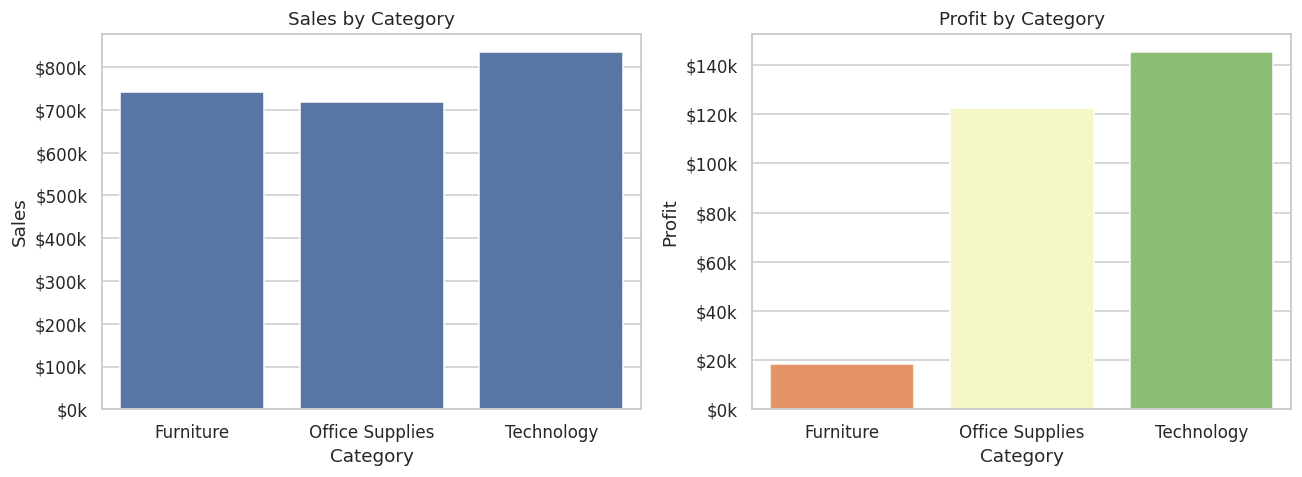

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(cat, x="Category", y="Sales", ax=axes[0])
axes[0].set_title("Sales by Category")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1000:,.0f}k"))

sns.barplot(cat, x="Category", y="Profit", ax=axes[1], palette="RdYlGn", hue="Category", legend=False)
axes[1].set_title("Profit by Category")
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1000:,.0f}k"))
plt.tight_layout()
plt.show()

**Insight — Furniture is a profitability trap:** Furniture generates almost as much revenue as
Technology (**$742k vs $836k**), but produces only **$18.5k profit (≈2.5% margin)** compared to
Technology's **$145k (≈17.4% margin)**. Furniture sales *look* healthy on a revenue report but are
barely breaking even.

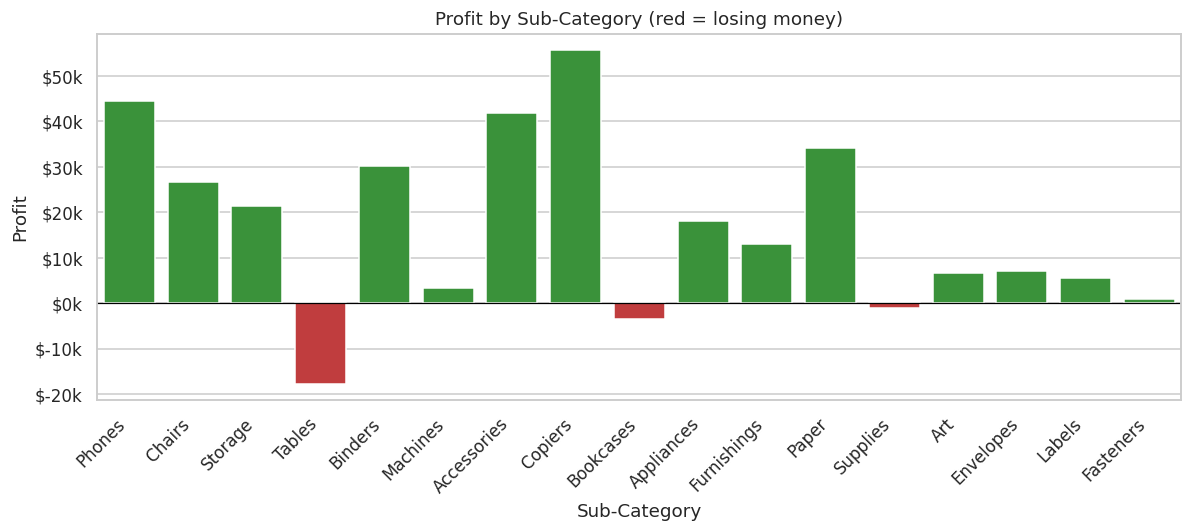

,Sub-Category,Sales,Profit,Profit Margin %
16,Tables,206965.5320,-17725.4811,-8.6
4,Bookcases,114879.9963,-3472.5560,-3.0
15,Supplies,46673.5380,-1189.0995,-2.5


In [9]:
subcat = sa.by_subcategory(df)
subcat["Profit Margin %"] = (subcat["Profit"] / subcat["Sales"] * 100).round(1)

fig, ax = plt.subplots(figsize=(11, 5))
colors = ["#d62728" if p < 0 else "#2ca02c" for p in subcat["Profit"]]
sns.barplot(subcat, x="Sub-Category", y="Profit", palette=colors, hue="Sub-Category", legend=False, ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Profit by Sub-Category (red = losing money)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1000:,.0f}k"))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

subcat[subcat["Profit"] < 0][["Sub-Category", "Sales", "Profit", "Profit Margin %"]]

**Insight — the root cause is identified:** three sub-categories are **losing money outright**:
**Tables (-$17.7k)**, **Bookcases (-$3.5k)**, and **Supplies (-$1.2k)**. Tables alone erase almost all
of Furniture's other profit. *Recommendation: renegotiate supplier costs for Tables/Bookcases, or cap
discounts specifically on these two sub-categories (see Section 6 for why discounting is the likely
cause).*

## 6. Discount Impact on Profitability

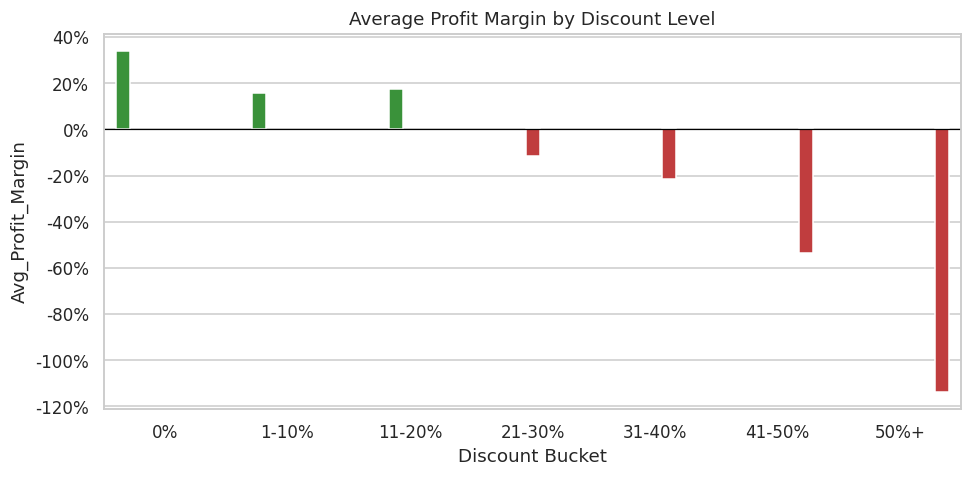

,Discount Bucket,Avg_Profit_Margin,Orders
0,0%,0.340160,2644
1,1-10%,0.155795,89
2,11-20%,0.174839,2436
3,21-30%,-0.115484,211
4,31-40%,-0.216908,211
5,41-50%,-0.535586,74
6,50%+,-1.138785,685


In [10]:
disc = sa.discount_profit_relationship(df)

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["#d62728" if m < 0 else "#2ca02c" for m in disc["Avg_Profit_Margin"]]
sns.barplot(disc, x="Discount Bucket", y="Avg_Profit_Margin", palette=colors, hue="Discount Bucket", legend=False, ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Average Profit Margin by Discount Level")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x*100:.0f}%"))
plt.tight_layout()
plt.show()
disc

**Insight — there is a clear discount "tipping point":** orders with **0-20% discount stay
profitable** (13-34% margin), but average margin **turns negative once discounts exceed ~20%**, and
craters to **-114% margin** for discounts of 50%+. This strongly suggests discounting — not weak
demand — is the direct cause of the Tables/Bookcases losses found in Section 5.
*Recommendation: introduce a maximum-discount approval threshold (e.g. 20%) for
sales reps, especially on Furniture sub-categories.*

## 7. Customer Segment Analysis (Consumer / Corporate / Home Office)

In [11]:
seg = sa.by_segment(df)
seg

,Segment,Sales,Profit,Sales_to_Profit_Ratio
0,Consumer,1.161401e+06,134119.2092,8.66
1,Corporate,7.061464e+05,91979.1340,7.68
2,Home Office,4.296531e+05,60298.6785,7.13


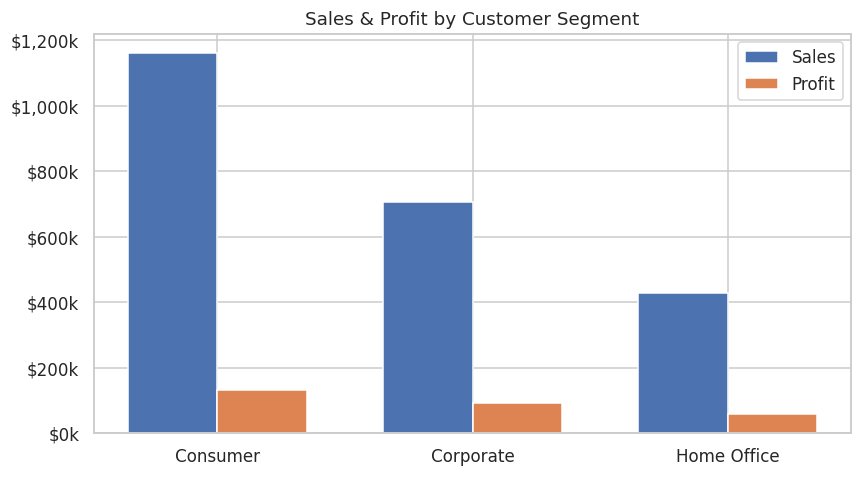

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = range(len(seg))
width = 0.35
ax.bar([i - width/2 for i in x], seg["Sales"], width, label="Sales")
ax.bar([i + width/2 for i in x], seg["Profit"], width, label="Profit")
ax.set_xticks(list(x))
ax.set_xticklabels(seg["Segment"])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v/1000:,.0f}k"))
ax.set_title("Sales & Profit by Customer Segment")
ax.legend()
plt.tight_layout()
plt.show()

**Insight:** the **Consumer** segment drives the most revenue and profit in absolute terms, but
**Home Office** is the most profit-*efficient* segment relative to its size (lowest sales-to-profit
ratio at 7.13, vs. 8.66 for Consumer) — meaning each Home Office dollar of sales converts to profit
more efficiently. *Recommendation: this segment may be under-invested in relative to its return.*

## 8. Customer Value: RFM Segmentation

We now move from *transaction-level* to *customer-level* analysis using **RFM segmentation**
(Recency, Frequency, Monetary) — a standard marketing-analytics technique that groups each of the
793 customers into an actionable segment such as *Champions*, *Loyal Customers*, *At Risk*, or *Lost*,
based on how recently, how often, and how much they buy.

In [13]:
rfm = cs.compute_rfm(df)
seg_summary = cs.segment_summary(rfm)
seg_summary

,Segment,Customers,Avg_Monetary,Avg_Frequency,Avg_Recency
0,Loyal Customers,204,3443.47,8.28,35.45
1,Needs Attention,195,2775.16,5.38,165.29
2,Lost,179,1015.32,3.92,322.64
3,At Risk,107,4959.72,8.31,170.62
4,New Customers,74,1915.96,4.55,16.11
5,Champions,34,5863.65,10.09,16.00


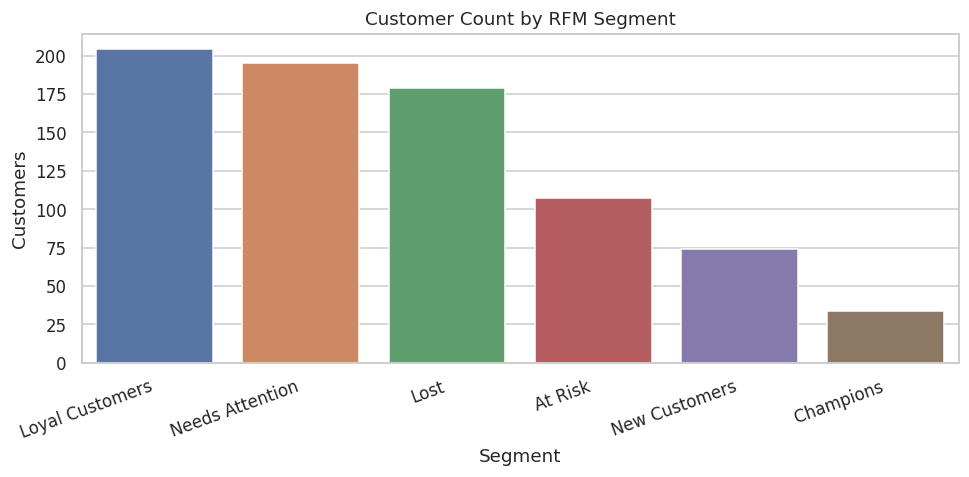

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.5))
order = seg_summary.sort_values("Customers", ascending=False)
sns.barplot(order, x="Segment", y="Customers", hue="Segment", legend=False, ax=ax)
ax.set_title("Customer Count by RFM Segment")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

**Insight:** only **34 customers (4.3%) are "Champions"**, yet they average **$5,864** in
lifetime sales each — more than any other group. Meanwhile **107 customers (13.5%) are "At Risk"**:
historically high spenders ($4,960 avg) who haven't ordered in **~171 days on average**.
*Recommendation: prioritize a win-back campaign for the At-Risk segment before they become fully
Lost — recovering even a fraction of these 107 customers is worth far more than acquiring new ones.*

## 9. Geographic Analysis (Sales & Profit by State)

In [15]:
geo = ga.state_summary(df)
top_bottom = ga.top_bottom_states(df, n=5)

print("Top 5 states by profit:")
display(top_bottom["top_profit"])
print("\nBottom 5 states by profit:")
display(top_bottom["bottom_profit"])

Top 5 states by profit:


,State,Sales,Profit
3,California,457687.6315,76381.3871
30,New York,310876.2710,74038.5486
45,Washington,138641.2700,33402.6517
20,Michigan,76269.6140,24463.1876
44,Virginia,70636.7200,18597.9504



Bottom 5 states by profit:


,State,Sales,Profit
41,Texas,170188.0458,-25729.3563
33,Ohio,78258.1360,-16971.3766
36,Pennsylvania,116511.9140,-15559.9603
11,Illinois,80166.1010,-12607.8870
31,North Carolina,55603.1640,-7490.9122


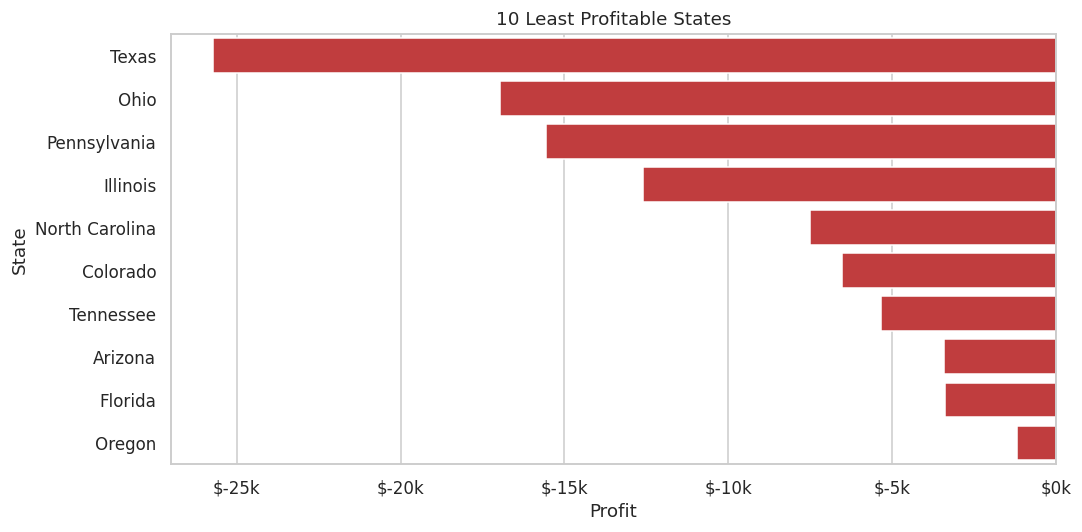

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
worst = geo.nsmallest(10, "Profit").sort_values("Profit")
colors = ["#d62728" if p < 0 else "#2ca02c" for p in worst["Profit"]]
sns.barplot(worst, x="Profit", y="State", palette=colors, hue="State", legend=False, ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("10 Least Profitable States")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1000:,.0f}k"))
plt.tight_layout()
plt.show()

**Insight — high sales does not guarantee profit, regionally either:** **Texas** ($170k sales)
and **Pennsylvania** ($117k sales) both post **negative overall profit** (-$25.7k and -$15.6k
respectively), likely driven by the same aggressive-discounting pattern seen in Section 6.
Meanwhile **California** and **New York** are both high-sales *and* high-profit — the healthiest
markets. *Recommendation: audit discount approval practices specifically in Texas and Pennsylvania
sales teams.*

## 10. Sales Forecasting (Next 6 Months)

Using **Holt-Winters Exponential Smoothing** (trend + yearly seasonality) on the full monthly
sales history, we project the next 6 months. This method was chosen over a black-box AutoML approach
because it explicitly models the strong seasonality identified in Section 4, and is fast, transparent,
and easy to explain to a non-technical stakeholder.

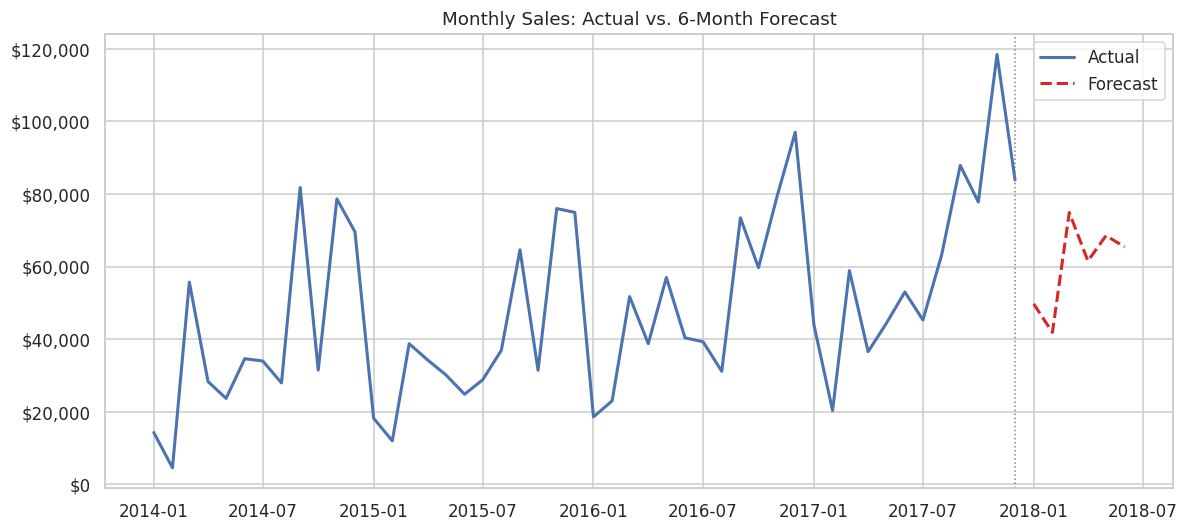

/tmp/ipykernel_699/1231766249.py:15: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  forecast[["Date", "Sales"]].rename(columns={"Sales": "Forecasted Sales"}).round(0)


,Date,Forecasted Sales
48,2018-01-01,49693.0
49,2018-02-01,41840.0
50,2018-03-01,74875.0
51,2018-04-01,61539.0
52,2018-05-01,68509.0
53,2018-06-01,65397.0


In [17]:
forecast_df = fc.forecast_sales(df, periods=6)

fig, ax = plt.subplots(figsize=(11, 5))
actual = forecast_df[forecast_df["Type"] == "Actual"]
forecast = forecast_df[forecast_df["Type"] == "Forecast"]
ax.plot(actual["Date"], actual["Sales"], label="Actual", linewidth=2)
ax.plot(forecast["Date"], forecast["Sales"], label="Forecast", linewidth=2, linestyle="--", color="#d62728")
ax.axvline(actual["Date"].iloc[-1], color="gray", linestyle=":", linewidth=1)
ax.set_title("Monthly Sales: Actual vs. 6-Month Forecast")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
ax.legend()
plt.tight_layout()
plt.show()

forecast[["Date", "Sales"]].rename(columns={"Sales": "Forecasted Sales"}).round(0)

**Insight:** the model correctly captures the recurring **January/February post-holiday dip**
and projects a partial recovery into spring, consistent with the historical seasonal pattern.
*Recommendation: plan reduced inventory purchasing and staffing for Q1, and pre-position holiday
inventory earlier given the consistent Nov/Dec spike.*

## 11. Executive Summary & Business Recommendations

| # | Finding | Recommendation |
|---|---|---|
| 1 | Sales are strongly seasonal, peaking every Nov–Dec | Align inventory & marketing spend with the seasonal cycle |
| 2 | Furniture generates high revenue but near-zero profit (2.5% margin) | Review Furniture pricing/supplier costs |
| 3 | Tables & Bookcases lose money outright | Cap discount approval on these two sub-categories |
| 4 | Profit margin turns negative once discounts exceed ~20% | Introduce a max-discount policy (~20%) requiring manager approval above it |
| 5 | Home Office segment converts sales to profit most efficiently | Consider increased investment/marketing toward Home Office customers |
| 6 | 107 "At Risk" customers were historically high-value but haven't ordered in ~171 days | Launch a targeted win-back email/discount campaign |
| 7 | Texas & Pennsylvania have high sales but negative profit | Audit regional discounting practices in these states |
| 8 | Forecast shows a predictable Q1 dip | Adjust inventory & staffing planning for the seasonal trough |

---
*For live, filterable exploration of every chart above, see the companion Streamlit dashboard:
`streamlit run dashboard/app.py`.*
